# 6001CMD – Hotel Booking Demand Analysis

Dataset: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

1. Upload and Load the Dataset

In [5]:
# Upload the CSV file from your computer.
from google.colab import files

uploaded = files.upload()

Saving hotel_bookings.csv to hotel_bookings.csv


In [6]:
import pandas as pd

# Read the CSV into a table called df.
df = pd.read_csv("hotel_bookings.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


2. Dataset Overview

In [7]:
# Show the number of records.
print(f"Booking records: {df.shape[0]:,}")
# Show the number of columns.
print(f"Columns: {df.shape[1]}")

# Show the number of bookings for each hotel.
print("\nBooking counts by hotel:")
print(df["hotel"].value_counts().to_string())

# Combine the arrival year, month and day into one date.
arrival_dates = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"].astype(str) + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
    errors="coerce"
)

print("\nScheduled arrival period:")
print(f"Earliest: {arrival_dates.min():%d %B %Y}")
print(f"Latest: {arrival_dates.max():%d %B %Y}")
print(f"Unparsed dates: {arrival_dates.isna().sum()}")

Booking records: 119,390
Columns: 32

Booking counts by hotel:
hotel
City Hotel      79330
Resort Hotel    40060

Scheduled arrival period:
Earliest: 01 July 2015
Latest: 31 August 2017
Unparsed dates: 0


3. Cancellation Class Distribution

          Outcome  Count Percentage
Not cancelled (0)  75166     62.96%
    Cancelled (1)  44224     37.04%


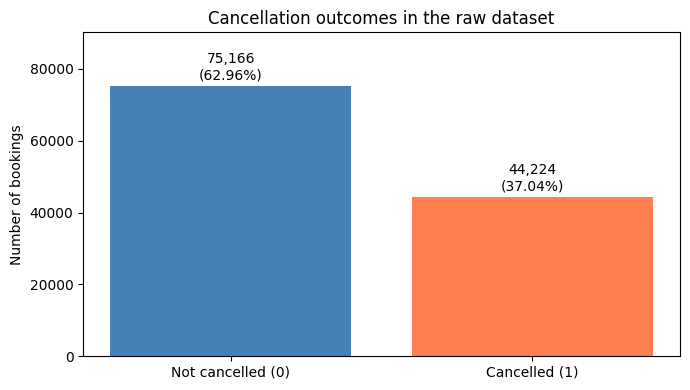

In [8]:
import matplotlib.pyplot as plt

# Count non-cancelled (0) and cancelled (1) bookings.
counts = df["is_canceled"].value_counts().reindex([0, 1], fill_value=0)

summary = pd.DataFrame({
    "Outcome": ["Not cancelled (0)", "Cancelled (1)"],
    "Count": counts.to_numpy(),
    "Percentage": (counts / len(df) * 100).to_numpy()
})

print(summary.to_string(
    index=False,
    formatters={"Percentage": lambda x: f"{x:.2f}%"}
))

# Create a bar chart with one bar for each outcome.
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    summary["Outcome"],
    summary["Count"],
    color=["steelblue", "coral"]
)

for bar, count, percentage in zip(
    bars, summary["Count"], summary["Percentage"]
):
    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_ylabel("Number of bookings")
ax.set_title("Cancellation outcomes in the raw dataset")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

4. Missing Values

In [9]:
# Count the missing values in each column.
missing_counts = df.isna().sum()

missing_summary = pd.DataFrame({
    "Missing records": missing_counts,
    "Percentage": missing_counts / len(df) * 100
})

# Show only columns that contain missing values.
missing_summary = missing_summary[
    missing_summary["Missing records"] > 0
].sort_values("Missing records", ascending=False)

print(missing_summary.to_string(
    formatters={"Percentage": lambda x: f"{x:.4f}%"}
))

          Missing records Percentage
company            112593   94.3069%
agent               16340   13.6862%
country               488    0.4087%
children                4    0.0034%


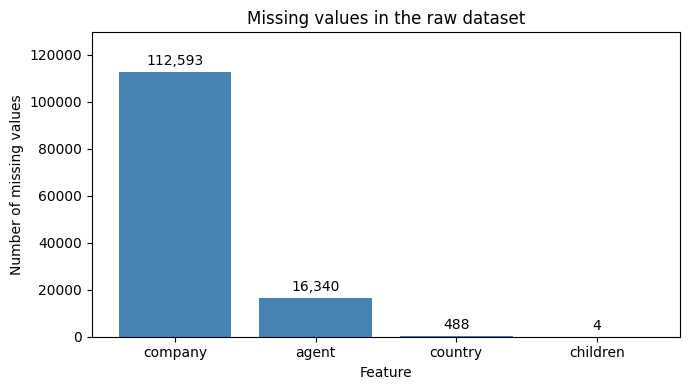

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    missing_summary.index,
    missing_summary["Missing records"],
    color="steelblue"
)

# Display the missing-value count above each bar.
for bar, count in zip(bars, missing_summary["Missing records"]):
    ax.annotate(
        f"{count:,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

# Add axis labels and a chart title.
ax.set_xlabel("Feature")
ax.set_ylabel("Number of missing values")
ax.set_title("Missing values in the raw dataset")

# Leave space above the tallest bar for its count label.
ax.set_ylim(0, missing_summary["Missing records"].max() * 1.15)

plt.tight_layout()
plt.show()

5. Repeated Records

In [11]:
# Count rows that match an earlier row in every column.
repeated_rows = df.duplicated().sum()
repeated_percentage = repeated_rows / len(df) * 100

print(f"Total records: {len(df):,}")
print(f"Rows repeating an earlier row: {repeated_rows:,}")
print(f"Percentage: {repeated_percentage:.2f}%")

Total records: 119,390
Rows repeating an earlier row: 31,994
Percentage: 26.80%


6. Numerical Summaries and Distributions

In [12]:
# Choose the three numerical columns to examine.
features = ["lead_time", "adr", "days_in_waiting_list"]

numerical_summary = pd.DataFrame({
    "Minimum": df[features].min(),
    "Median": df[features].median(),
    "Maximum": df[features].max(),
    "Skewness": df[features].skew()
})

print(numerical_summary.to_string(
    float_format=lambda x: f"{x:.3f}"
))

                      Minimum  Median  Maximum  Skewness
lead_time               0.000  69.000  737.000     1.347
adr                    -6.380  94.575 5400.000    10.530
days_in_waiting_list    0.000   0.000  391.000    11.944


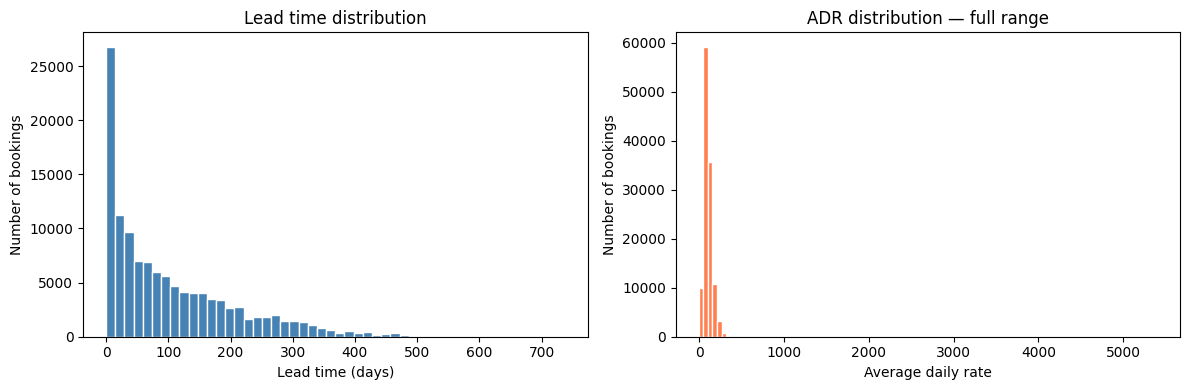

In [13]:
import matplotlib.pyplot as plt

# Create two graphs side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Group lead-time values into 50 intervals.
# Each bar shows how many bookings fall within that interval.
axes[0].hist(df["lead_time"].dropna(), bins=50,
             color="steelblue", edgecolor="white")
axes[0].set_title("Lead time distribution")
axes[0].set_xlabel("Lead time (days)")
axes[0].set_ylabel("Number of bookings")

# Group ADR values into 100 intervals.
# Include the full range, including negative and extreme values.
axes[1].hist(df["adr"].dropna(), bins=100,
             color="coral", edgecolor="white")
axes[1].set_title("ADR distribution — full range")
axes[1].set_xlabel("Average daily rate")
axes[1].set_ylabel("Number of bookings")

plt.tight_layout()
plt.show()

7. Correlation Analysis

Selected Pearson correlations:
lead_time vs is_canceled: 0.293
total_of_special_requests vs is_canceled: -0.235
stays_in_week_nights vs stays_in_weekend_nights: 0.499


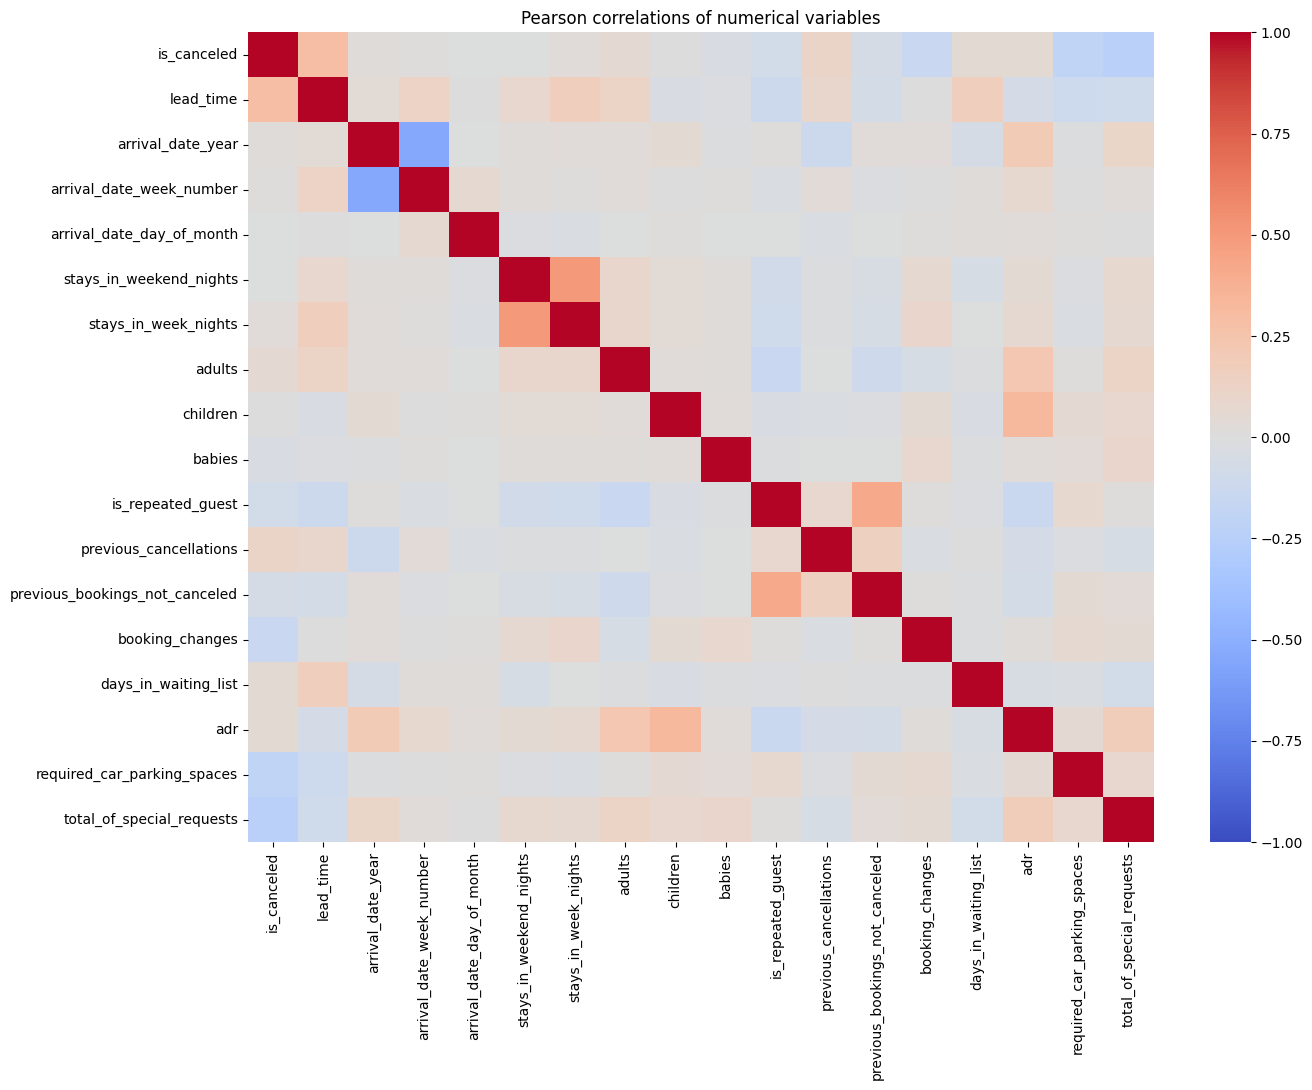

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude agent and company IDs because their numbers are labels, not quantities suitable for Pearson correlation.
correlation = (
    df.select_dtypes(include="number")
    .drop(columns=["agent", "company"])
    .corr()
)

print("Selected Pearson correlations:")

# Relationship between lead time and cancellation.
print(
    "lead_time vs is_canceled:",
    f"{correlation.loc['lead_time', 'is_canceled']:.3f}"
)

# Relationship between special requests and cancellation.
print(
    "total_of_special_requests vs is_canceled:",
    f"{correlation.loc['total_of_special_requests', 'is_canceled']:.3f}"
)

# Relationship between weekday and weekend stay lengths.
print(
    "stays_in_week_nights vs stays_in_weekend_nights:",
    f"{correlation.loc['stays_in_week_nights', 'stays_in_weekend_nights']:.3f}"
)

# Display all calculated correlations in a heatmap.
# Red shows positive relationships; blue shows negative relationships.
# Values near zero indicate little linear association.
plt.figure(figsize=(14, 11))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Pearson correlations of numerical variables")
plt.tight_layout()
plt.show()

8. Possible Data Inconsistencies

In [15]:
# Require all three guest counts to be present before summing
total_guests = df[["adults", "children", "babies"]].sum(
    axis=1, min_count=3
)

print(f"Records with negative ADR: {(df['adr'] < 0).sum():,}")
print(f"Records with ADR above 1,000: {(df['adr'] > 1000).sum():,}")
print(f"Maximum number of adults: {df['adults'].max():,}")
print(f"Records with zero total guests: {(total_guests == 0).sum():,}")

Records with negative ADR: 1
Records with ADR above 1,000: 1
Maximum number of adults: 55
Records with zero total guests: 180


9. Preprocessing Demonstration

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Select numerical columns: these values measure days or guest counts.
numeric_features = [
    "lead_time", "stays_in_week_nights",
    "stays_in_weekend_nights", "adults", "children", "babies"
]

# Select categorical columns: these values identify groups or types.
categorical_features = [
    "hotel", "meal", "market_segment",
    "distribution_channel", "reserved_room_type", "country", "agent"
]

# X contains the selected information used as model inputs.
X = df[numeric_features + categorical_features].copy()

# y contains the outcome we would predict: cancellation.
y = df["is_canceled"]

# Convert agent IDs to text.
# Keep missing entries missing so we can fill them later.
X["agent"] = X["agent"].map(
    lambda value: str(int(value)) if pd.notna(value) else value
)

# Put 80% of bookings in the training set and 20% in the test set.
# Split the input features (X) and their matching labels (y) together.
# stratify=y keeps similar cancellation percentages in both sets.
# random_state=42 makes the split repeatable.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Find the median number of children using training data only.
children_median = X_train["children"].median()

# Apply these steps to both the training and test sets.
for split in [X_train, X_test]:

    # Fill missing children values with the training-set median.
    split["children"] = split["children"].fillna(children_median)

    # Add weekday and weekend nights to get the total stay length.
    split["total_stay_nights"] = (
        split["stays_in_week_nights"] +
        split["stays_in_weekend_nights"]
    )

    # Add adults, children and babies to get the total guest count.
    split["total_guests"] = (
        split["adults"] + split["children"] + split["babies"]
    )

# Include the two new columns in numerical preprocessing.
numeric_features += ["total_stay_nights", "total_guests"]

# Apply different preprocessing steps to each column type.
preprocessor = ColumnTransformer([

    # For numerical columns:
    # 1. Fill missing values with the training-set median.
    # 2. Standardise values so the columns have comparable scales.
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    # For categorical columns:
    # 1. Fill missing values with "Unknown".
    # 2. Create a separate indicator column for each category.
    # If a new category appears in test data, avoid raising an error.
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant", fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Learn medians, scaling values and categories from training data.
# Then use these settings to transform the training data.
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same training-data settings.
X_test_processed = preprocessor.transform(X_test)

print(f"Training records: {len(X_train):,}")
print(f"Test records: {len(X_test):,}")
print(f"Training-set children median: {children_median}")
print(f"Transformed training shape: {X_train_processed.shape}")
print(f"Transformed test shape: {X_test_processed.shape}")
print("Imputation, encoding and scaling completed.")
print("Preprocessing parameters fitted on training data only.")

print("\nExamples of engineered features:")
print(X_train[
    ["total_stay_nights", "total_guests"]
].head().to_string(index=False))

Training records: 95,512
Test records: 23,878
Training-set children median: 0.0
Transformed training shape: (95512, 539)
Transformed test shape: (23878, 539)
Imputation, encoding and scaling completed.
Preprocessing parameters fitted on training data only.

Examples of engineered features:
 total_stay_nights  total_guests
                 2           1.0
                 3           2.0
                 3           2.0
                14           2.0
                 1           1.0
